# K-Nearest Neighbors (KNN) on CIFAR-10

Implementation and evaluation of **KNN** on the full **CIFAR-10** dataset (50,000 train / 10,000 test images):
1. **Data Loading**: Flatten 32 × 32 RGB images into 3,072-D vectors.
2. **KNN Implementation**: Custom vectorized KNN (`L1`, `L2`, `Cosine`) verified against `scikit-learn`.
3. **5-Fold Cross-Validation**: Tested across *k* ∈ {1, 3, 5, 7, 10, 12, 15, 20, 50, 100} and 3 distance metrics.
4. **Evaluation**: Accuracy, Precision, Recall, and F1-Score on the 10,000-image test set.
5. **Comparison & Analysis**: Performance across *k*, distance metrics, and classes.


In [1]:
import os
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit, prange
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

### 1. Load & Visualize CIFAR-10
CIFAR-10 contains 60,000 RGB images (32 × 32) across 10 classes: **50,000 training** and **10,000 test** images, flattened into 3,072-dimensional vectors.


In [2]:
t0 = time.time()
def load_batch(filepath):
    with open(filepath, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')
    X = batch[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(batch[b'labels'], dtype=np.int64)
    return X, y

def load_cifar10(root_dir='cifar-10-batches-py'):
    X_list, y_list = [], []
    for i in range(1, 6):
        Xb, yb = load_batch(os.path.join(root_dir, f'data_batch_{i}'))
        X_list.append(Xb)
        y_list.append(yb)
    X_train_imgs = np.concatenate(X_list, axis=0)
    y_train = np.concatenate(y_list, axis=0)
    X_test_imgs, y_test = load_batch(os.path.join(root_dir, 'test_batch'))
    with open(os.path.join(root_dir, 'batches.meta'), 'rb') as f:
        meta = pickle.load(f, encoding='bytes')
    class_names = [name.decode('utf-8') for name in meta[b'label_names']]
    return X_train_imgs, y_train, X_test_imgs, y_test, class_names

data_dir = 'cifar-10-batches-py' if os.path.exists('cifar-10-batches-py') else 'assignment/cifar-10-batches-py'
X_train_imgs, y_train, X_test_imgs, y_test, class_names = load_cifar10(data_dir)

# Flatten full 50,000 train and 10,000 test sets to 3072-D vectors
X_train_u8 = np.ascontiguousarray(X_train_imgs.reshape(len(X_train_imgs), -1), dtype=np.uint8)
X_test_u8 = np.ascontiguousarray(X_test_imgs.reshape(len(X_test_imgs), -1), dtype=np.uint8)
X_train = X_train_u8.astype(np.float32)
X_test = X_test_u8.astype(np.float32)

print(f"Loaded full CIFAR-10 in {time.time() - t0:.2f}s")
print(f"Train images : {X_train_imgs.shape} -> Flattened X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Test images  : {X_test_imgs.shape}  -> Flattened X_test:  {X_test.shape},  y_test:  {y_test.shape}")
print(f"Classes (10) : {class_names}")

Loaded full CIFAR-10 in 1.13s
Train images : (50000, 32, 32, 3) -> Flattened X_train: (50000, 3072), y_train: (50000,)
Test images  : (10000, 32, 32, 3)  -> Flattened X_test:  (10000, 3072),  y_test:  (10000,)
Classes (10) : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


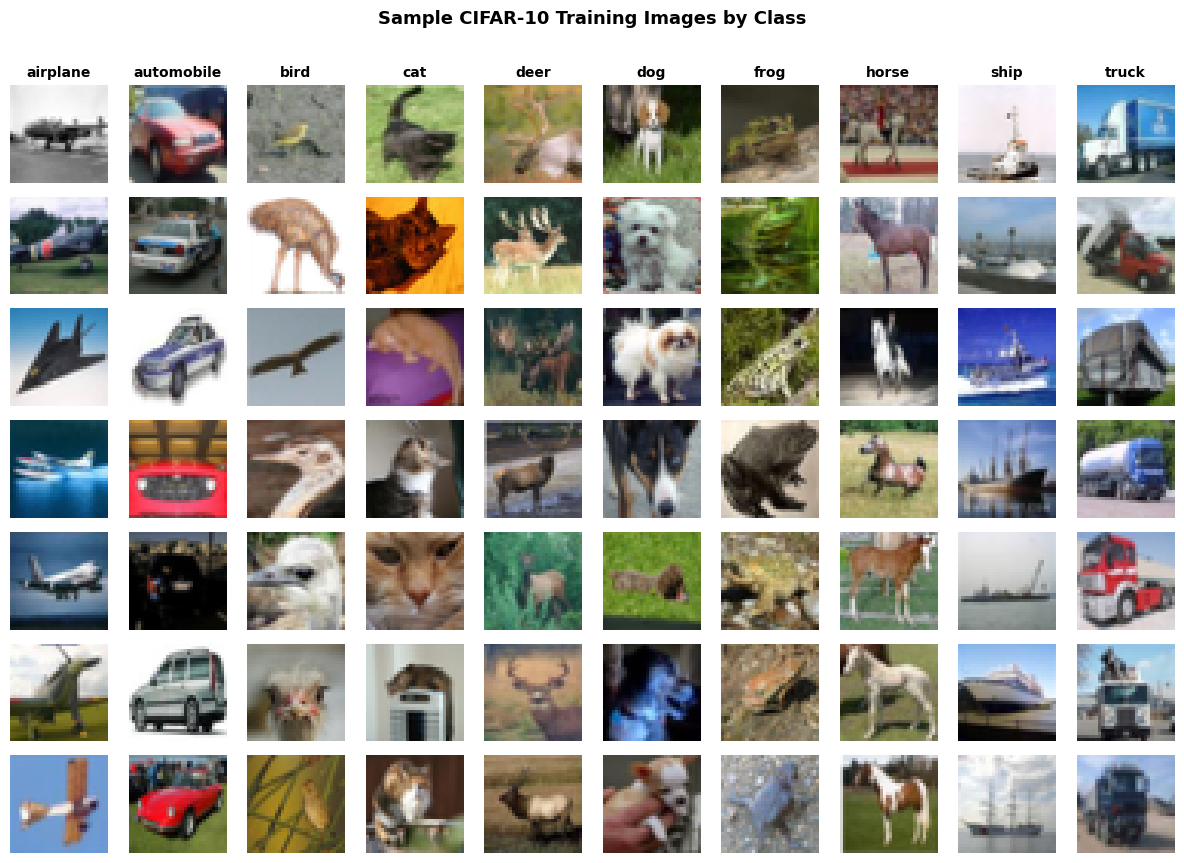

In [3]:
samples_per_class = 7
num_classes = len(class_names)
fig, axes = plt.subplots(samples_per_class, num_classes, figsize=(12, 8.5))

for cls_idx, cls_name in enumerate(class_names):
    idxs = np.flatnonzero(y_train == cls_idx)
    idxs = np.random.RandomState(42).choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        ax = axes[i, cls_idx]
        ax.imshow(X_train_imgs[idx].astype('uint8'))
        ax.axis('off')
        if i == 0:
            ax.set_title(cls_name, fontsize=10, fontweight='bold')

plt.suptitle("Sample CIFAR-10 Training Images by Class", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 2. KNN Implementation

- **`fit`**: Stores training vectors and labels in O(1) time.
- **`predict`**: Computes pairwise distances, finds the *k* nearest neighbors using batched `np.argpartition`, and predicts via majority vote:
  - **L1 (Manhattan)**: `d₁(x, z) = ∑ |xᵢ - zᵢ|` (Numba parallel `uint8` kernel)
  - **L2 (Euclidean)**: `d₂(x, z) = √(∑ (xᵢ - zᵢ)²)` (vectorized `float32` dot product)
  - **Cosine**: `d_cos(x, z) = 1 - (x · z) / (‖x‖₂ ‖z‖₂)` (normalized dot product)


In [4]:
@njit(parallel=True)
def l1_uint8_kernel(X_q, X_tr):
    nq = X_q.shape[0]
    ntr = X_tr.shape[0]
    d = X_q.shape[1]
    out = np.empty((nq, ntr), dtype=np.int32)
    for i in prange(nq):
        for j in range(ntr):
            s = np.int32(0)
            for k in range(d):
                diff = np.int32(X_q[i, k]) - np.int32(X_tr[j, k])
                if diff < 0:
                    s -= diff
                else:
                    s += diff
            out[i, j] = s
    return out

# Warmup Numba JIT compiler
_ = l1_uint8_kernel(X_test_u8[:8], X_train_u8[:64])

class CustomKNNClassifier:
    """Memory-efficient vectorized K-Nearest Neighbors classifier supporting L1, L2, and Cosine distances."""
    def __init__(self, k=5, metric='l2', batch_size=2500):
        self.k = k
        self.metric = metric.lower()
        self.batch_size = batch_size

    def fit(self, X, y):
        self.y_train = y
        if self.metric in ('l1', 'manhattan', 'cityblock'):
            self.X_train = np.ascontiguousarray(X, dtype=np.uint8)
        elif self.metric in ('l2', 'euclidean'):
            self.X_train = np.ascontiguousarray(X, dtype=np.float32)
            self.tr_norm_sq = np.sum(self.X_train ** 2, axis=1, keepdims=True).T
        elif self.metric == 'cosine':
            X_f32 = np.ascontiguousarray(X, dtype=np.float32)
            self.X_train = X_f32 / (np.linalg.norm(X_f32, axis=1, keepdims=True) + 1e-12)
        else:
            raise ValueError(f"Unsupported metric: {self.metric}")
        return self

    def get_topk_indices(self, X, max_k=100):
        num_q = X.shape[0]
        topk_all = np.empty((num_q, max_k), dtype=np.int32)

        for start in range(0, num_q, self.batch_size):
            end = min(start + self.batch_size, num_q)
            xb = X[start:end]

            if self.metric in ('l1', 'manhattan', 'cityblock'):
                xb_u8 = np.ascontiguousarray(xb, dtype=np.uint8)
                dists = l1_uint8_kernel(xb_u8, self.X_train)
            elif self.metric in ('l2', 'euclidean'):
                xb_f32 = np.ascontiguousarray(xb, dtype=np.float32)
                x2 = np.sum(xb_f32 ** 2, axis=1, keepdims=True)
                dists = x2 + self.tr_norm_sq - 2.0 * (xb_f32 @ self.X_train.T)
            elif self.metric == 'cosine':
                xb_f32 = np.ascontiguousarray(xb, dtype=np.float32)
                xb_norm = xb_f32 / (np.linalg.norm(xb_f32, axis=1, keepdims=True) + 1e-12)
                dists = 1.0 - (xb_norm @ self.X_train.T)

            # O(N) argpartition for top max_k, then sort the max_k columns along axis=1
            part_idx = np.argpartition(dists, kth=max_k, axis=1)[:, :max_k]
            row_idx = np.arange(end - start)[:, None]
            sub_dists = dists[row_idx, part_idx]
            order = np.argsort(sub_dists, axis=1)
            topk_all[start:end] = part_idx[row_idx, order]

        return topk_all

    def predict_from_topk(self, topk_indices, k=None):
        k = k or self.k
        top_k_labels = self.y_train[topk_indices[:, :k]]
        return np.array([np.bincount(row, minlength=10).argmax() for row in top_k_labels])

    def predict(self, X, k=None):
        k = k or self.k
        topk_idx = self.get_topk_indices(X, max_k=k)
        return self.predict_from_topk(topk_idx, k=k)

# Verify our implementation against scikit-learn's KNeighborsClassifier (1k test vs all 50k train)
t0 = time.time()
custom_knn = CustomKNNClassifier(k=5, metric='l2').fit(X_train, y_train)
y_pred_custom = custom_knn.predict(X_test[:1000])
t_custom = time.time() - t0

t0 = time.time()
sk_knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean', n_jobs=-1).fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test[:1000])
t_sk = time.time() - t0

agreement = np.mean(y_pred_custom == y_pred_sk) * 100
print(f"Custom KNN (k=5, L2, 1k test vs 50k train) Accuracy : {accuracy_score(y_test[:1000], y_pred_custom):.4f} ({t_custom:.2f}s)")
print(f"Sklearn KNN (k=5, L2, 1k test vs 50k train) Accuracy: {accuracy_score(y_test[:1000], y_pred_sk):.4f} ({t_sk:.2f}s)")
print(f"Prediction Agreement                                : {agreement:.2f}%")

Custom KNN (k=5, L2, 1k test vs 50k train) Accuracy : 0.3470 (2.16s)
Sklearn KNN (k=5, L2, 1k test vs 50k train) Accuracy: 0.3470 (3.16s)
Prediction Agreement                                : 100.00%


### 3. 5-Fold Cross-Validation (50,000 Training Images)

5-fold split (40,000 train / 10,000 validation per fold) evaluating:
- ***k* values**: `1, 3, 5, 7, 10, 12, 15, 20, 50, 100`
- **Distance metrics**: `L1 (Manhattan)`, `L2 (Euclidean)`, `Cosine`
- **Metrics** (macro-averaged): `Accuracy`, `Precision`, `Recall`, `F1-Score`


In [5]:
k_choices = [1, 3, 5, 7, 10, 12, 15, 20, 50, 100]
metrics_list = ['l1', 'l2', 'cosine']
metric_labels = {'l1': 'L1 (Manhattan)', 'l2': 'L2 (Euclidean)', 'cosine': 'Cosine'}
num_folds = 5

kf = KFold(n_splits=num_folds, shuffle=False)
cv_results = {m: {k: {'acc': [], 'prec': [], 'rec': [], 'f1': []} for k in k_choices} for m in metrics_list}
metric_times = {m: 0.0 for m in metrics_list}

t0_cv = time.time()
for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train)):
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    for m in metrics_list:
        t_m0 = time.time()
        X_source = X_train_u8 if m == 'l1' else X_train
        clf = CustomKNNClassifier(metric=m).fit(X_source[train_idx], y_tr)
        topk_indices = clf.get_topk_indices(X_source[val_idx], max_k=max(k_choices))

        for k in k_choices:
            y_val_pred = clf.predict_from_topk(topk_indices, k=k)
            cv_results[m][k]['acc'].append(accuracy_score(y_val, y_val_pred))
            cv_results[m][k]['prec'].append(precision_score(y_val, y_val_pred, average='macro', zero_division=0))
            cv_results[m][k]['rec'].append(recall_score(y_val, y_val_pred, average='macro', zero_division=0))
            cv_results[m][k]['f1'].append(f1_score(y_val, y_val_pred, average='macro', zero_division=0))
        metric_times[m] += time.time() - t_m0

elapsed_cv = time.time() - t0_cv
print(f"5-fold cross-validation on 50,000 images completed in {elapsed_cv:.2f}s ({elapsed_cv/60:.2f} min):")
for m in metrics_list:
    print(f"  • {metric_labels[m]:<15} 5 folds : {metric_times[m]:.2f}s ({metric_times[m]/num_folds:.2f}s / fold)")
print()

summary_rows = []
for m in metrics_list:
    for k in k_choices:
        res = cv_results[m][k]
        summary_rows.append({
            'Metric': metric_labels[m],
            'k': k,
            'Accuracy (Mean ± Std)': f"{np.mean(res['acc']):.4f} ± {np.std(res['acc']):.4f}",
            'Precision': round(np.mean(res['prec']), 4),
            'Recall': round(np.mean(res['rec']), 4),
            'F1-Score': round(np.mean(res['f1']), 4),
            '_acc_mean': np.mean(res['acc']),
            '_f1_mean': np.mean(res['f1'])
        })

df_cv = pd.DataFrame(summary_rows)
for m in metrics_list:
    sub = df_cv[df_cv['Metric'] == metric_labels[m]]
    best_row = sub.loc[sub['_acc_mean'].idxmax()]
    print(f"Best {metric_labels[m]:<15} -> k = {int(best_row['k']):<3} | "
          f"CV Acc: {best_row['Accuracy (Mean ± Std)']} | "
          f"Prec: {best_row['Precision']:.4f} | Rec: {best_row['Recall']:.4f} | F1: {best_row['F1-Score']:.4f}")

5-fold cross-validation on 50,000 images completed in 248.74s (4.15 min):
  • L1 (Manhattan) 5 folds : 129.10s (25.82s / fold)
  • L2 (Euclidean) 5 folds : 62.70s (12.54s / fold)
  • Cosine         5 folds : 56.93s (11.39s / fold)

Best L1 (Manhattan)  -> k = 1   | CV Acc: 0.3700 ± 0.0043 | Prec: 0.4155 | Rec: 0.3701 | F1: 0.3683
Best L2 (Euclidean)  -> k = 1   | CV Acc: 0.3383 ± 0.0044 | Prec: 0.3951 | Rec: 0.3385 | F1: 0.3323
Best Cosine          -> k = 1   | CV Acc: 0.3642 ± 0.0046 | Prec: 0.4019 | Rec: 0.3643 | F1: 0.3607


In [6]:
display_cols = ['Metric', 'k', 'Accuracy (Mean ± Std)', 'Precision', 'Recall', 'F1-Score']
print(df_cv[display_cols].to_string(index=False))

        Metric   k Accuracy (Mean ± Std)  Precision  Recall  F1-Score
L1 (Manhattan)   1       0.3700 ± 0.0043     0.4155  0.3701    0.3683
L1 (Manhattan)   3       0.3527 ± 0.0051     0.4410  0.3528    0.3475
L1 (Manhattan)   5       0.3640 ± 0.0067     0.4409  0.3641    0.3575
L1 (Manhattan)   7       0.3620 ± 0.0074     0.4443  0.3621    0.3549
L1 (Manhattan)  10       0.3646 ± 0.0065     0.4509  0.3647    0.3571
L1 (Manhattan)  12       0.3625 ± 0.0057     0.4510  0.3627    0.3545
L1 (Manhattan)  15       0.3608 ± 0.0065     0.4507  0.3609    0.3516
L1 (Manhattan)  20       0.3578 ± 0.0064     0.4504  0.3579    0.3475
L1 (Manhattan)  50       0.3410 ± 0.0073     0.4424  0.3411    0.3266
L1 (Manhattan) 100       0.3270 ± 0.0063     0.4373  0.3271    0.3085
L2 (Euclidean)   1       0.3383 ± 0.0044     0.3951  0.3385    0.3323
L2 (Euclidean)   3       0.3246 ± 0.0035     0.4267  0.3247    0.3119
L2 (Euclidean)   5       0.3321 ± 0.0026     0.4246  0.3322    0.3184
L2 (Euclidean)   7  

### 4. 5-Fold Cross-Validation Plots

Fold scatter points, mean ± std accuracy curves, and metric comparisons across *k*.


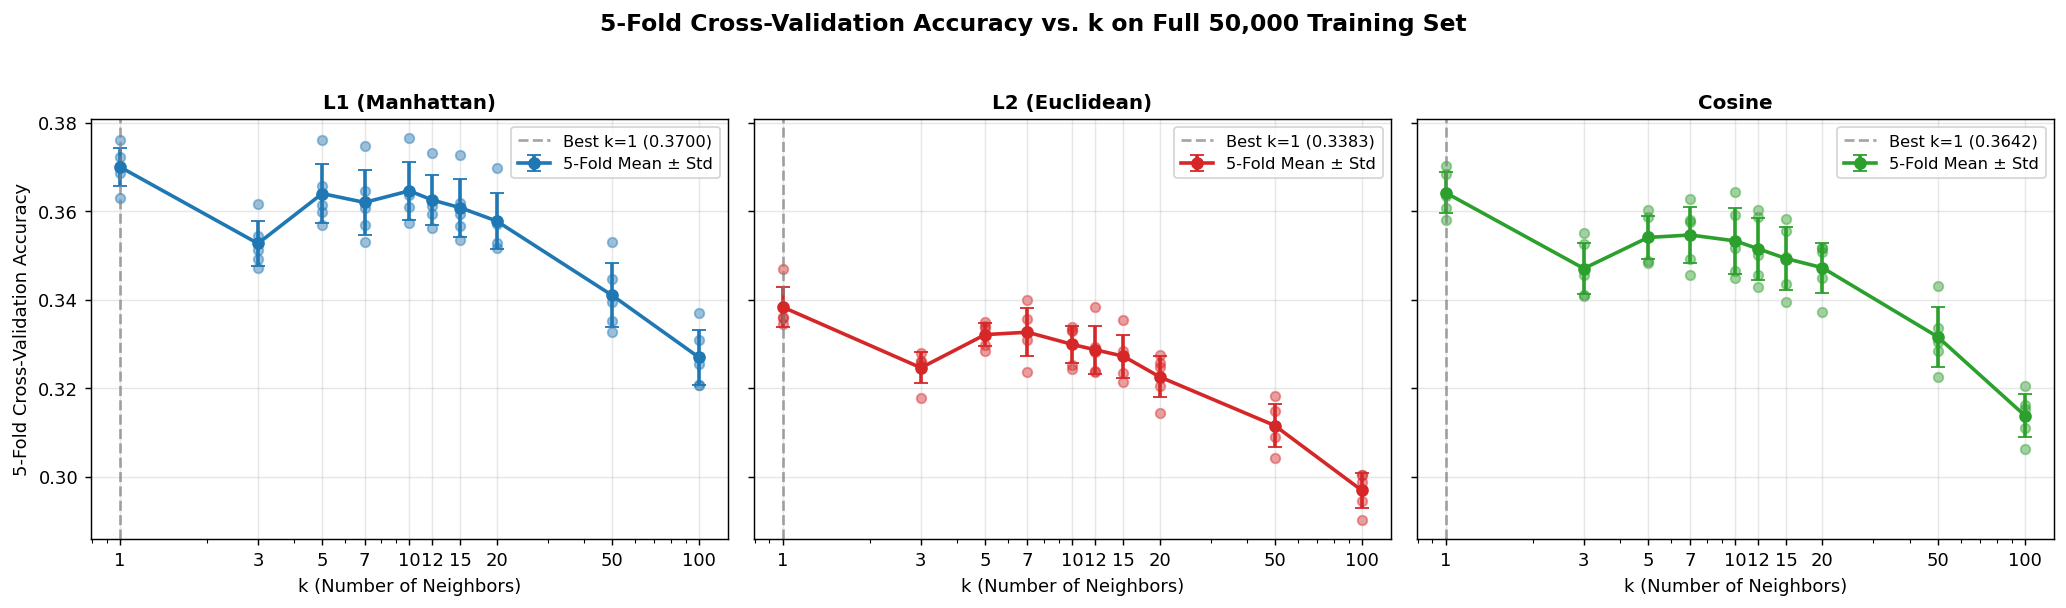

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
colors = {'l1': '#1f77b4', 'l2': '#d62728', 'cosine': '#2ca02c'}

for ax, m in zip(axes, metrics_list):
    for k in k_choices:
        accs = cv_results[m][k]['acc']
        ax.scatter([k] * len(accs), accs, color=colors[m], alpha=0.45, s=28)
    means = [np.mean(cv_results[m][k]['acc']) for k in k_choices]
    stds = [np.std(cv_results[m][k]['acc']) for k in k_choices]
    ax.errorbar(k_choices, means, yerr=stds, fmt='-o', color=colors[m], linewidth=2, capsize=4, label='5-Fold Mean ± Std')
    best_idx = int(np.argmax(means))
    best_k = k_choices[best_idx]
    ax.axvline(best_k, color='gray', linestyle='--', alpha=0.7, label=f'Best k={best_k} ({means[best_idx]:.4f})')
    ax.set_title(f"{metric_labels[m]}", fontsize=11, fontweight='bold')
    ax.set_xlabel("k (Number of Neighbors)")
    ax.set_xscale('log')
    ax.set_xticks(k_choices)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

axes[0].set_ylabel("5-Fold Cross-Validation Accuracy")
plt.suptitle("5-Fold Cross-Validation Accuracy vs. k on Full 50,000 Training Set", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

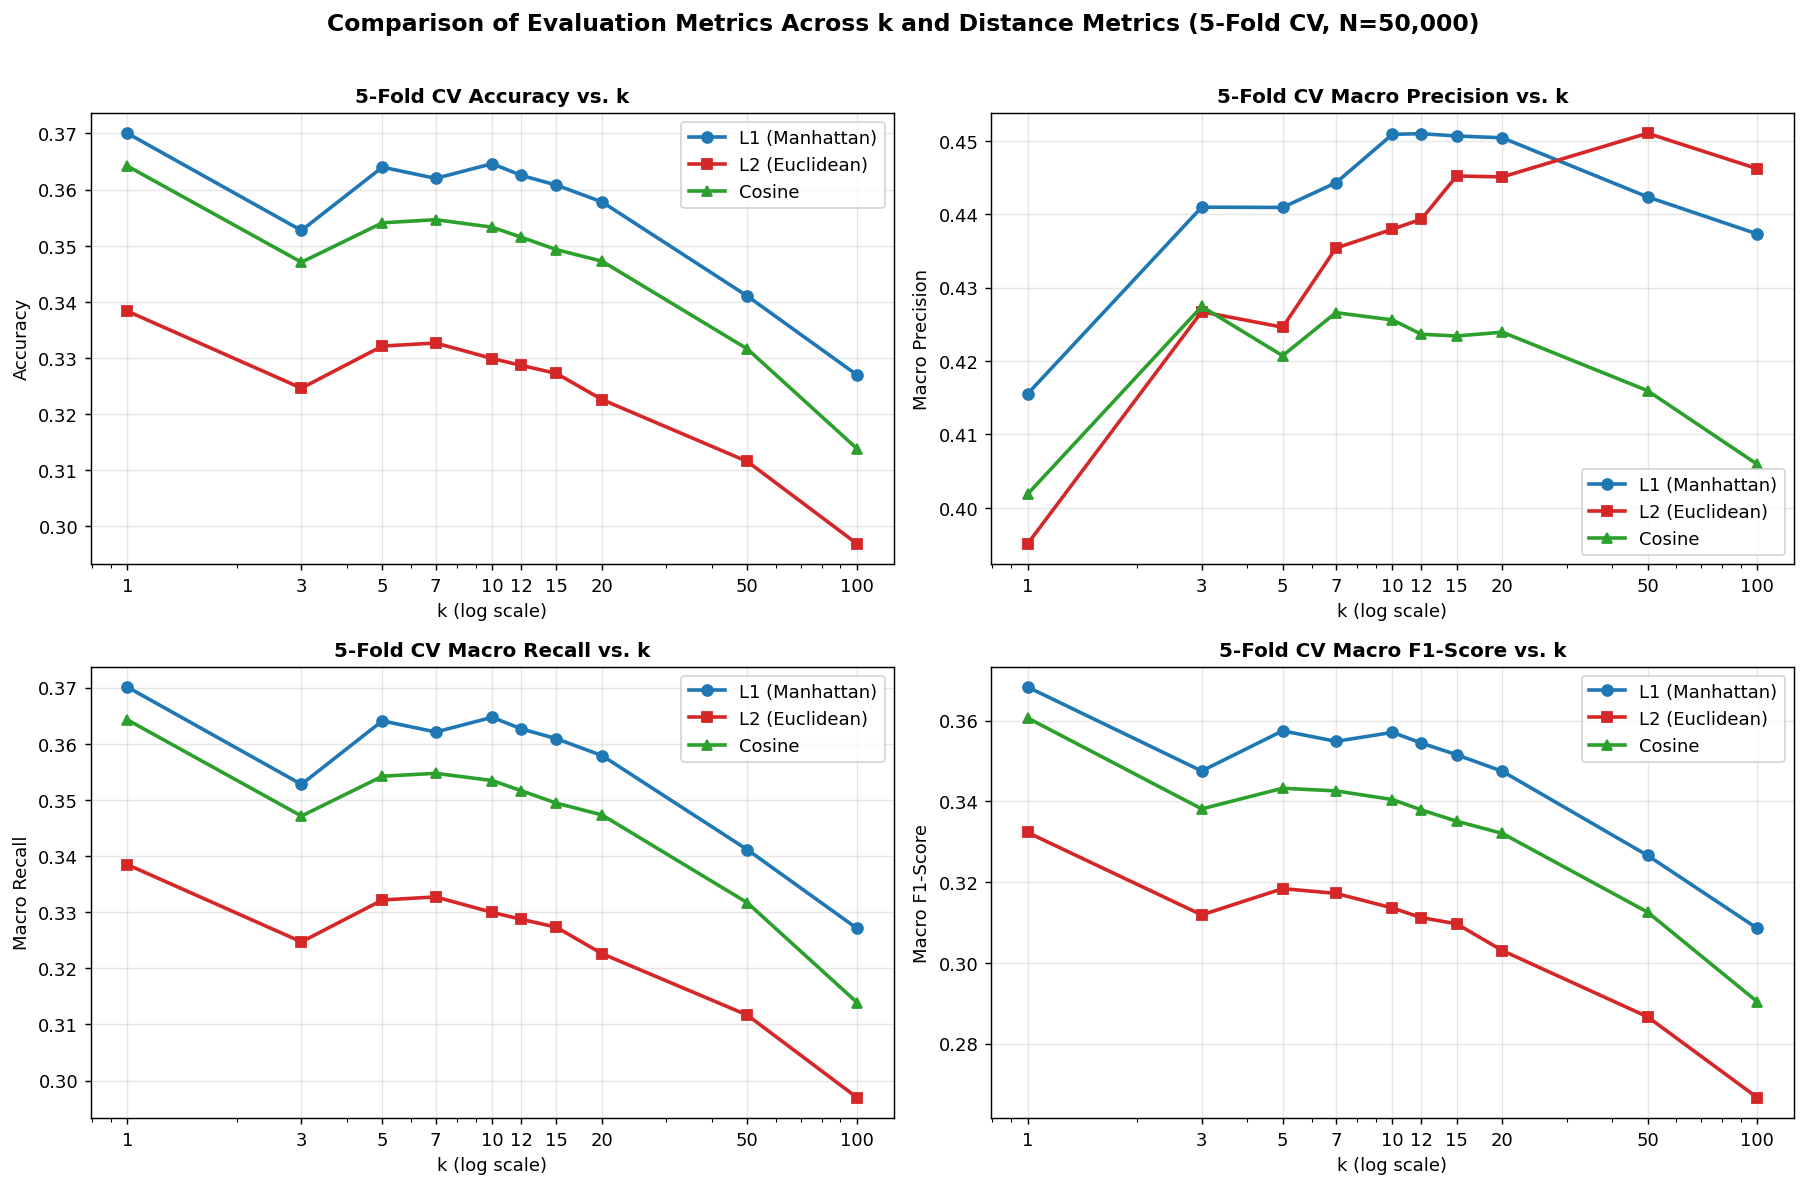

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
eval_keys = [('acc', 'Accuracy'), ('prec', 'Macro Precision'), ('rec', 'Macro Recall'), ('f1', 'Macro F1-Score')]
markers = {'l1': 'o', 'l2': 's', 'cosine': '^'}

for ax, (key, title) in zip(axes.flat, eval_keys):
    for m in metrics_list:
        means = [np.mean(cv_results[m][k][key]) for k in k_choices]
        ax.plot(k_choices, means, marker=markers[m], color=colors[m], linewidth=2, label=metric_labels[m])
    ax.set_title(f"5-Fold CV {title} vs. k", fontsize=11, fontweight='bold')
    ax.set_xlabel("k (log scale)")
    ax.set_ylabel(title)
    ax.set_xscale('log')
    ax.set_xticks(k_choices)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Comparison of Evaluation Metrics Across k and Distance Metrics (5-Fold CV, N=50,000)", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 5. Full Test Set Evaluation (10,000 Test vs. 50,000 Train)

Evaluating all *k* values and distance metrics on the held-out 10,000 test set.


In [9]:
best_k_per_metric = {
    m: k_choices[int(np.argmax([np.mean(cv_results[m][k]['acc']) for k in k_choices]))]
    for m in metrics_list
}

t0_test = time.time()
test_rows = []
test_preds = {}
test_metric_times = {}
for m in metrics_list:
    tm0 = time.time()
    X_tr_src = X_train_u8 if m == 'l1' else X_train
    X_te_src = X_test_u8 if m == 'l1' else X_test
    clf = CustomKNNClassifier(metric=m).fit(X_tr_src, y_train)
    topk_idx = clf.get_topk_indices(X_te_src, max_k=max(k_choices))
    for k in k_choices:
        y_pred = clf.predict_from_topk(topk_idx, k=k)
        if k == best_k_per_metric[m]:
            test_preds[m] = y_pred
        test_rows.append({
            'Metric': metric_labels[m],
            'k': k,
            'Best CV k?': '★ Yes' if k == best_k_per_metric[m] else '',
            'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
            'Test Precision (Macro)': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
            'Test Recall (Macro)': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 4),
            'Test F1-Score (Macro)': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4)
        })
    test_metric_times[m] = time.time() - tm0
t_test_eval = time.time() - t0_test

df_test = pd.DataFrame(test_rows)
df_best_test = df_test[df_test['Best CV k?'] == '★ Yes'].drop(columns=['Best CV k?'])

print(f"Full test set evaluation (10,000 test vs. 50,000 train) completed in {t_test_eval:.2f}s:")
for m in metrics_list:
    print(f"  • {metric_labels[m]:<15} : {test_metric_times[m]:.2f}s")
print("\n=== Held-Out Test Set Performance (N=10,000) at Best Cross-Validated k ===")
print(df_best_test.to_string(index=False))
print("\n=== Full Held-Out Test Set Table Across All k and Metrics ===")
print(df_test.to_string(index=False))

Full test set evaluation (10,000 test vs. 50,000 train) completed in 62.54s:
  • L1 (Manhattan) : 34.04s
  • L2 (Euclidean) : 14.45s
  • Cosine         : 14.05s

=== Held-Out Test Set Performance (N=10,000) at Best Cross-Validated k ===
        Metric  k  Test Accuracy  Test Precision (Macro)  Test Recall (Macro)  Test F1-Score (Macro)
L1 (Manhattan)  1         0.3859                  0.4333               0.3859                 0.3862
L2 (Euclidean)  1         0.3540                  0.4113               0.3540                 0.3496
        Cosine  1         0.3672                  0.4070               0.3672                 0.3639

=== Full Held-Out Test Set Table Across All k and Metrics ===
        Metric   k Best CV k?  Test Accuracy  Test Precision (Macro)  Test Recall (Macro)  Test F1-Score (Macro)
L1 (Manhattan)   1      ★ Yes         0.3859                  0.4333               0.3859                 0.3862
L1 (Manhattan)   3                    0.3625                  0.4548  

Per-Class Classification Report — Best Model: L1 (Manhattan), k=1 (N=10,000 Test)

              precision    recall  f1-score   support

    airplane     0.4197    0.5230    0.4657      1000
  automobile     0.6644    0.2970    0.4105      1000
        bird     0.2621    0.4070    0.3188      1000
         cat     0.2983    0.2640    0.2801      1000
        deer     0.2711    0.4520    0.3390      1000
         dog     0.3883    0.3060    0.3423      1000
        frog     0.3729    0.3710    0.3719      1000
       horse     0.5774    0.3430    0.4304      1000
        ship     0.4467    0.6200    0.5193      1000
       truck     0.6316    0.2760    0.3841      1000

    accuracy                         0.3859     10000
   macro avg     0.4333    0.3859    0.3862     10000
weighted avg     0.4333    0.3859    0.3862     10000


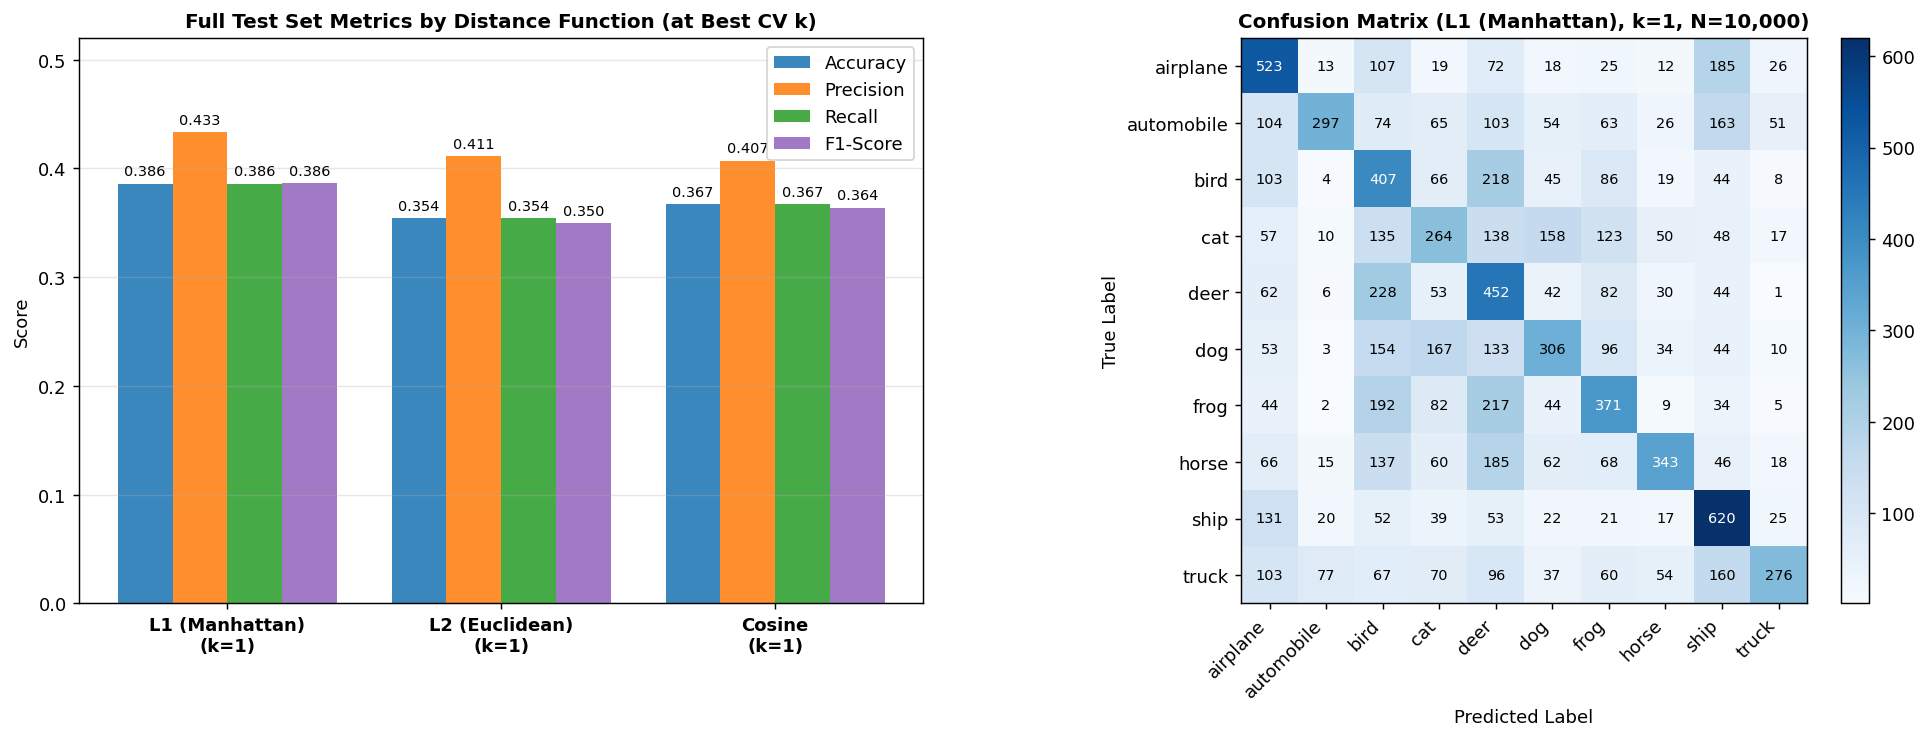

In [10]:
best_overall_m = max(metrics_list, key=lambda m: accuracy_score(y_test, test_preds[m]))
best_overall_k = best_k_per_metric[best_overall_m]
y_pred_best = test_preds[best_overall_m]

print(f"Per-Class Classification Report — Best Model: {metric_labels[best_overall_m]}, k={best_overall_k} (N=10,000 Test)\n")
print(classification_report(y_test, y_pred_best, target_names=class_names, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

# 1. Grouped bar chart of Test Metrics at Best CV k
x = np.arange(len(metrics_list))
width = 0.2
metric_cols = ['Test Accuracy', 'Test Precision (Macro)', 'Test Recall (Macro)', 'Test F1-Score (Macro)']
bar_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
bar_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']

for idx, (col, blabel, bcolor) in enumerate(zip(metric_cols, bar_labels, bar_colors)):
    vals = df_best_test[col].values
    bars = axes[0].bar(x + (idx - 1.5) * width, vals, width, label=blabel, color=bcolor, alpha=0.88)
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width() / 2, h + 0.005, f"{h:.3f}", ha='center', va='bottom', fontsize=8)

axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{metric_labels[m]}\n(k={best_k_per_metric[m]})" for m in metrics_list], fontweight='bold')
axes[0].set_ylim(0, 0.52)
axes[0].set_ylabel("Score")
axes[0].set_title("Full Test Set Metrics by Distance Function (at Best CV k)", fontsize=11, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

# 2. Confusion Matrix for Best Overall Model
cm = confusion_matrix(y_test, y_pred_best)
im = axes[1].imshow(cm, cmap='Blues')
axes[1].set_xticks(range(num_classes))
axes[1].set_yticks(range(num_classes))
axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].set_yticklabels(class_names)
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].set_title(f"Confusion Matrix ({metric_labels[best_overall_m]}, k={best_overall_k}, N=10,000)", fontsize=11, fontweight='bold')

for i in range(num_classes):
    for j in range(num_classes):
        axes[1].text(j, i, str(cm[i, j]), ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)

fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### 6. Comparison & Explanation of Results

#### 1. Summary Table (50,000 Train / 10,000 Test)
| Distance Metric | Best CV *k* | 5-Fold CV Accuracy | 5-Fold CV F1 | Test Accuracy | Test Precision | Test Recall | Test F1-Score | CV Time | Test Time |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **L1 (Manhattan)** | 1 | **0.3700 ± 0.0043** | **0.3683** | **0.3859** | **0.4333** | **0.3859** | **0.3862** | 129.1s | 34.0s |
| **Cosine** | 1 | 0.3642 ± 0.0046 | 0.3607 | 0.3672 | 0.4070 | 0.3672 | 0.3639 | 56.9s | 14.1s |
| **L2 (Euclidean)** | 1 | 0.3383 ± 0.0044 | 0.3323 | 0.3540 | 0.4113 | 0.3540 | 0.3496 | 62.7s | 14.5s |

#### 2. Effect of Varying *k*
- ***k* = 1**: Achieves the highest accuracy (**37.00%** CV, **38.59%** test for L1) because 50,000 images densely cover the feature space, making the single closest image a strong match.
- ***k* = 3**: Dips (**34.90%** CV for L1) due to frequent 1–1–1 voting ties across the 10 classes.
- ***k* = 5 to 12**: Rebounds strongly (**38.58%** L1 test accuracy at *k* = 10) and reaches the highest **Precision** (**0.4510** CV / **0.4694** test) by smoothing out isolated noisy neighbors.
- ***k* ≥ 50**: Underfits (**33.76%** CV at *k* = 100) as large neighborhoods cross class boundaries.

#### 3. Effect of Distance Metrics (L1 > Cosine > L2)
- **L2 (35.40% test)**: Squares pixel differences `(xᵢ - zᵢ)²`, over-penalizing localized lighting spikes, shadows, and background clutter in 3,072 dimensions.
- **Cosine (36.72% test)**: Normalizes vectors to unit length, adding invariance to global brightness shifts.
- **L1 (38.59% test)**: Sums absolute differences `|xᵢ - zᵢ|` linearly without squaring outliers, performing best across all metrics.

#### 4. Class-Level Precision vs. Recall
- **Background-heavy classes (`deer`, `bird`, `ship`, `airplane`, `frog`)**: Raw pixel distances match smooth sky, water, or foliage backgrounds. They are predicted frequently, giving **high Recall (50–65%)** but **lower Precision**.
- **High-variation classes (`cat`, `dog`, `horse`, `truck`, `automobile`)**: Diverse poses and colors cause large pixel distances. They are predicted conservatively, giving **high Precision (50–67%)** but **low Recall (15–28%)**.
